# Unsupervised competitive category learning

Anonymous units learn from complete feature observations. Training receives feature indices with no category labels. After training, a separate evaluation uses synthetic labels to describe the units and compare completion with the supervised reference.

The supplied feature vocabulary and number of units remain experimental choices. The default uses three units. Random positive feature weights break symmetry. Temperature controls competition, and a homeostatic penalty reduces the activity of recently overused units. Learned unit numbers carry no predefined species meaning.

This notebook runs several fixed random seeds and uses the first for the demonstration. It reports every seed and selects none using category agreement or held-out completion. Equations use `$$ ... $$` for display math and `$ ... $` for inline math.

In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment

ROOT = Path.cwd().resolve()
if (ROOT / "BayesContourProcessing" / "contour_models").is_dir():
    ROOT = ROOT / "BayesContourProcessing"
while not (ROOT / "contour_models" / "face_recipes_and_observations.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the contour-processing project.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from contour_models.face_recipes_and_observations import *
from contour_models.hebbian_category_priors import CompetitiveHebbianPrior
from contour_models.vsa_inference import PixelVSA, posterior, mean_field
OUT = ROOT / "outputs" / "competitive"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## Settings and training observations

The learning rate sets prototype adaptation per example. Lower temperature sharpens competition. Homeostasis encourages unit usage, which is an additional modeling assumption and can oppose unequal category frequencies. The training stream is shuffled on every epoch. Multiple epochs revisit the same examples. Completion uses the original renderer and candidate inference.

The generator uses category-dependent distributions to construct its synthetic dataset. The competitive learner receives only the resulting feature rows. Its method signatures accept no category-label argument.

In [2]:
SEED = 7
MODEL_SEEDS = (0, 1, 2)
N_UNITS = 3
EPOCHS = 20
LEARNING_RATE = .03
TEMPERATURE = .7
HOMEOSTASIS = 2.0
USAGE_RATE = .02
LOW_USAGE_THRESHOLD = .05
N_TRAIN_PER_CLASS = 250
IMAGE_SIZE = 40
VSA_DIM = 512
VISIBILITIES = (.05, .10, .20)
TRIALS_PER_VISIBILITY = 9
FLIP_PROBABILITY = .05

library = make_library(size=IMAGE_SIZE, seed=SEED)
training_ids, evaluation_labels = sample_training(library, N_TRAIN_PER_CLASS, seed=SEED+4)
training_features = library.states[training_ids]
assert set(training_ids).isdisjoint(set(library.test_ids))
print("Training feature matrix:", training_features.shape)
print("Labels are retained separately for evaluation and the supervised reference.")

Training feature matrix: (750, 6)
Labels are retained separately for evaluation and the supervised reference.


## Competitive activation and Hebbian adaptation

For a feature vector $z$, unit $c$ receives the training score

$$
g_c(z)=\sum_j\log w_{cj,z_j}+\log\pi_c-\gamma\log(Ku_c).
$$

Here $w$ contains normalized feature preferences, $\pi$ is the accumulated unit-frequency estimate, $u$ is a recent usage trace, and $K$ is the number of units. The penalty reduces the score of an overused unit. Soft competition gives

$$
s_c=\frac{\exp(g_c/T)}{\sum_d\exp(g_d/T)}.
$$

Each feature group then adapts through co-activation and activity-dependent normalization

$$
w_{cjv}\leftarrow w_{cjv}+\eta s_c(a_{jv}-w_{cjv}).
$$

The feature activity $a_{jv}$ is one for the observed feature value. The negative term keeps the group normalized. The code applies a small positivity floor for stable logarithms. Usage follows an exponential moving average. Accumulated unit activities determine mixture weights.

At inference, the learned probabilities supply a categorical mixture prior. The homeostatic penalty and competition temperature govern training. They are excluded from the probabilistic mixture readout. This competitive update has no guarantee of monotone likelihood improvement or semantic categories.

Completed seed 0 with 15000 observations including repeats
Completed seed 1 with 15000 observations including repeats
Completed seed 2 with 15000 observations including repeats


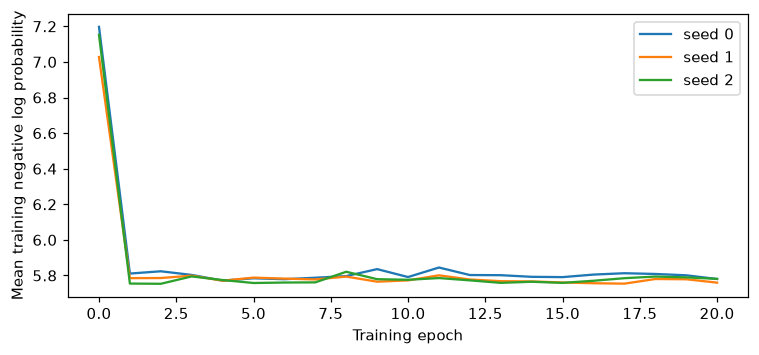

In [3]:
models = {}
training_history = []
for model_seed in MODEL_SEEDS:
    model = CompetitiveHebbianPrior(
        CARDINALITIES, n_units=N_UNITS, learning_rate=LEARNING_RATE,
        temperature=TEMPERATURE, homeostasis=HOMEOSTASIS,
        usage_rate=USAGE_RATE, seed=model_seed)
    shuffle_rng = np.random.default_rng(model_seed)
    for epoch in range(EPOCHS+1):
        if epoch:
            model.partial_fit(training_features[shuffle_rng.permutation(len(training_features))])
        log_probability = logsumexp(model.class_log_probabilities(training_features)
                                   + np.log(model.category_probabilities[:, None]), axis=0)
        training_history.append(dict(seed=model_seed, epoch=epoch,
                                     training_nll=float(-log_probability.mean())))
    models[model_seed] = model
    print("Completed seed", model_seed, "with", model.n_samples_seen, "observations including repeats")

fig, ax = plt.subplots(figsize=(7, 3.3))
for model_seed in MODEL_SEEDS:
    history = [r for r in training_history if r['seed'] == model_seed]
    ax.plot([r['epoch'] for r in history], [r['training_nll'] for r in history],
            label=f"seed {model_seed}")
ax.set(xlabel="Training epoch", ylabel="Mean training negative log probability")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "training_history.png", dpi=160); plt.show()

## Learned preferences and unit usage

The heatmaps show the first preselected seed. Unit rows remain anonymous. Hard-assignment occupancy uses the most probable mixture unit for each training feature row after training. Soft activity accumulated during training can be distributed even when a unit rarely wins, so both quantities are shown. The low-usage threshold is a descriptive diagnostic.

seed 0 hard occupancy [0.335 0.307 0.359] mean training activity [0.34  0.313 0.347] units below threshold 0
seed 1 hard occupancy [0.313 0.337 0.349] mean training activity [0.329 0.342 0.329] units below threshold 0
seed 2 hard occupancy [0.352 0.307 0.341] mean training activity [0.339 0.332 0.329] units below threshold 0


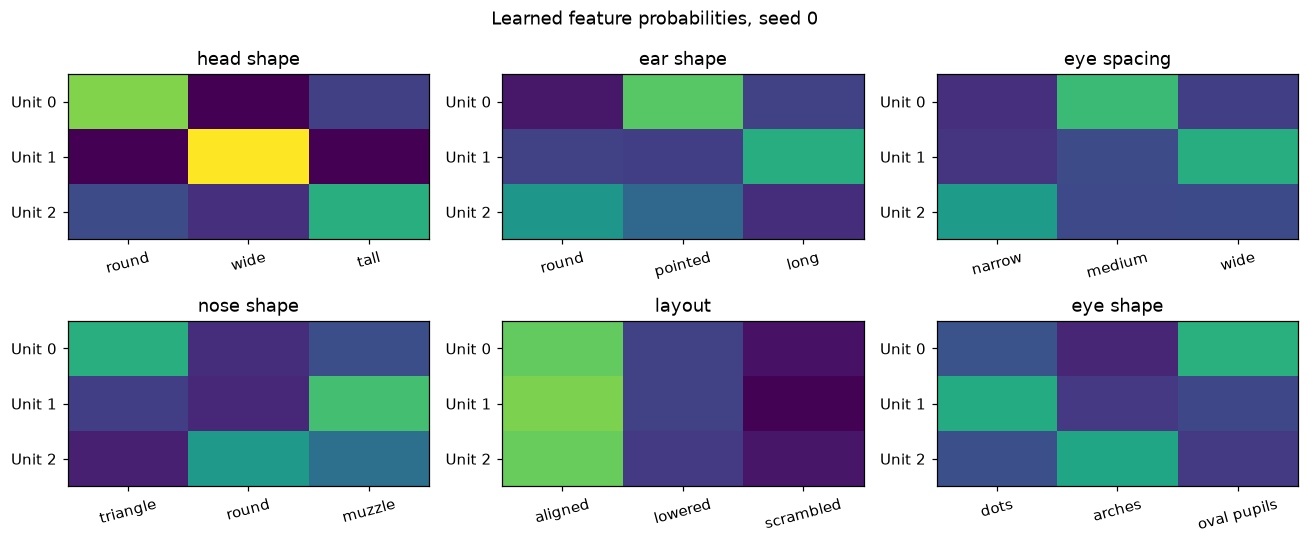

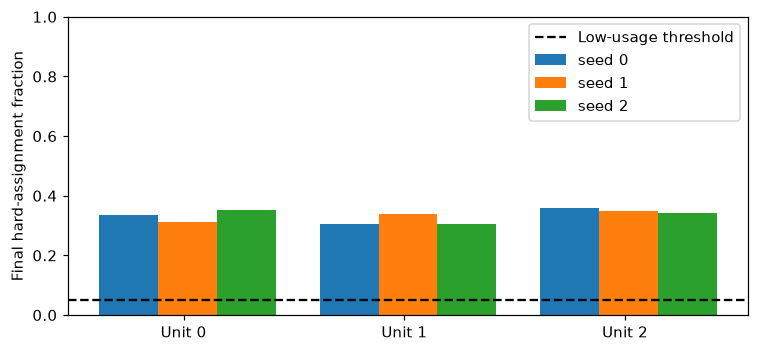

In [4]:
first_seed = MODEL_SEEDS[0]
model = models[first_seed]
fig, axes = plt.subplots(2, 3, figsize=(12, max(5, N_UNITS*1.2)))
for j, ax in enumerate(axes.flat):
    im = ax.imshow(model.feature_probabilities[j], vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(np.arange(CARDINALITIES[j]), FACTOR_VALUES[j], rotation=15)
    ax.set_yticks(np.arange(N_UNITS), [f"Unit {c}" for c in range(N_UNITS)])
    ax.set_title(FACTOR_NAMES[j])
fig.suptitle(f"Learned feature probabilities, seed {first_seed}")
fig.tight_layout(); fig.savefig(OUT / "unit_preferences.png", dpi=160); plt.show()

occupancy_by_seed = {}
for model_seed, trained in models.items():
    winners = trained.predict_proba(training_features).argmax(axis=1)
    occupancy = np.bincount(winners, minlength=N_UNITS) / len(winners)
    occupancy_by_seed[model_seed] = occupancy
    print("seed", model_seed, "hard occupancy", occupancy.round(3),
          "mean training activity", (trained.activity_totals/trained.n_samples_seen).round(3),
          "units below threshold", int((occupancy < LOW_USAGE_THRESHOLD).sum()))
fig, ax = plt.subplots(figsize=(7, 3.3))
for i, model_seed in enumerate(MODEL_SEEDS):
    ax.bar(np.arange(N_UNITS)+i*.8/len(MODEL_SEEDS), occupancy_by_seed[model_seed],
           width=.8/len(MODEL_SEEDS), label=f"seed {model_seed}")
ax.set_xticks(np.arange(N_UNITS)+.25, [f"Unit {c}" for c in range(N_UNITS)])
ax.set(ylabel="Final hard-assignment fraction", ylim=(0, 1))
ax.axhline(LOW_USAGE_THRESHOLD, ls="--", color="black", label="Low-usage threshold")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "unit_occupancy.png", dpi=160); plt.show()

## Post-training comparison with synthetic categories

Freeze each model first. The evaluation then finds a one-to-one alignment between anonymous units and training labels using a confusion matrix. Apply that alignment to held-out complete feature observations. This alignment changes evaluation names only. It never changes the units, weights, priors, or completion input. With more units than labels, unmatched units count as incorrect under this diagnostic. Category overlap in the generator also affects agreement.

In [5]:
trials = sample_trials(library, TRIALS_PER_VISIBILITY, VISIBILITIES,
                       seed=SEED+100, flip_probability=FLIP_PROBABILITY)
evaluation_features = library.states[[t['index'] for t in trials]]
heldout_labels = np.array([t['category'] for t in trials])
evaluation_summaries = []
for model_seed, trained in models.items():
    train_winners = trained.predict_proba(training_features).argmax(axis=1)
    confusion = np.zeros((len(CLASS_NAMES), N_UNITS), dtype=int)
    np.add.at(confusion, (evaluation_labels, train_winners), 1)
    class_indices, unit_indices = linear_sum_assignment(-confusion)
    unit_to_class = np.full(N_UNITS, -1, dtype=int)
    unit_to_class[unit_indices] = class_indices
    winners = trained.predict_proba(evaluation_features).argmax(axis=1)
    agreement = float(np.mean(unit_to_class[winners] == heldout_labels))
    evaluation_summaries.append(dict(seed=model_seed, heldout_aligned_agreement=agreement,
        low_usage_units=int((occupancy_by_seed[model_seed] < LOW_USAGE_THRESHOLD).sum()),
        occupancy=occupancy_by_seed[model_seed].tolist()))
    print("seed", model_seed, "training confusion (rows=categories, columns=anonymous units)")
    print(confusion)
    print("Post-hoc aligned agreement on held-out full features:", round(agreement, 3))

seed 0 training confusion (rows=categories, columns=anonymous units)
[[ 28 187  35]
 [208  29  13]
 [ 15  14 221]]
Post-hoc aligned agreement on held-out full features: 0.778
seed 1 training confusion (rows=categories, columns=anonymous units)
[[  7  30 213]
 [198  11  41]
 [ 30 212   8]]
Post-hoc aligned agreement on held-out full features: 0.815
seed 2 training confusion (rows=categories, columns=anonymous units)
[[ 41 202   7]
 [ 21  21 208]
 [202   7  41]]
Post-hoc aligned agreement on held-out full features: 0.741


## Completion on the same held-out observations

Compare uniform preferences, supervised Hebbian learning, and every competitive seed on the same noisy image fragments. Completion receives pixels, a known mask, and a learned prior. It receives no category labels or unit cues. Hidden truth enters the metrics after prediction. We report hidden Brier score, recovered strokes, and invented strokes separately. Nine trials per visibility is an exploratory sample.

uniform {'hidden_brier': 0.0145, 'hidden_recall': 0.8277, 'hidden_false_positive': 0.0038}
supervised {'hidden_brier': 0.0123, 'hidden_recall': 0.8806, 'hidden_false_positive': 0.007}
competitive_0 {'hidden_brier': 0.0129, 'hidden_recall': 0.8817, 'hidden_false_positive': 0.008}
competitive_1 {'hidden_brier': 0.0132, 'hidden_recall': 0.8656, 'hidden_false_positive': 0.0089}
competitive_2 {'hidden_brier': 0.0141, 'hidden_recall': 0.8618, 'hidden_false_positive': 0.0097}


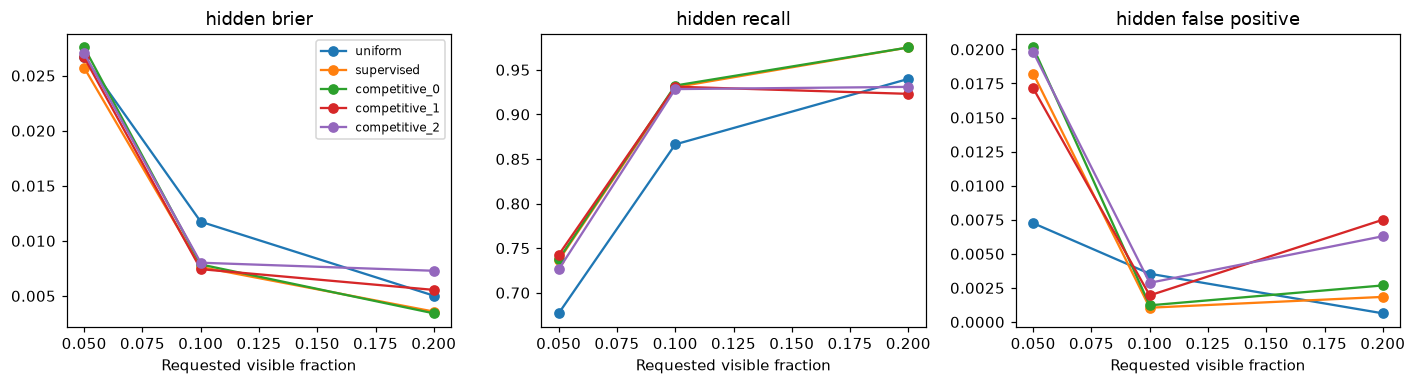

In [6]:
supervised = fit_priors(library, training_ids, evaluation_labels, category_learning="hebbian")
priors = {"uniform": supervised.logpriors['uniform'],
          "supervised": supervised.logpriors['category']}
priors.update({f"competitive_{s}": m.log_prior(library.states) for s, m in models.items()})
encoder = PixelVSA(IMAGE_SIZE, VSA_DIM, seed=SEED+10)
before_counts = {s: m.n_samples_seen for s, m in models.items()}
rows = []
for trial_id, trial in enumerate(trials):
    for backend in ("pixels", "vsa"):
        ll = encoder.evidence_scores(library.images, trial['observed'], trial['mask'],
                                     FLIP_PROBABILITY, backend)
        for name, logprior in priors.items():
            q = posterior(ll, logprior)
            metrics = completion_metrics(prediction(q, library.images), trial['truth'],
                                          trial['observed'], trial['mask'])
            rows.append(dict(trial=trial_id, visibility=trial['visibility'], backend=backend,
                             learner=name, **metrics))
assert before_counts == {s: m.n_samples_seen for s, m in models.items()}
with (OUT / "completion_metrics.csv").open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader(); writer.writerows(rows)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, metric in zip(axes, ('hidden_brier', 'hidden_recall', 'hidden_false_positive')):
    for name in priors:
        values = [np.mean([r[metric] for r in rows if r['backend']=='vsa' and
                          r['learner']==name and r['visibility']==v]) for v in VISIBILITIES]
        ax.plot(VISIBILITIES, values, 'o-', label=name)
    ax.set(xlabel="Requested visible fraction", title=metric.replace('_', ' '))
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "completion_metrics.png", dpi=160); plt.show()
for name in priors:
    selected = [r for r in rows if r['backend']=='vsa' and r['learner']==name]
    print(name, {metric:round(float(np.mean([r[metric] for r in selected])), 4)
                for metric in ('hidden_brier','hidden_recall','hidden_false_positive')})

## Example reconstruction and iterative inference

The stimulus below is selected for display from the held-out cow-like distribution. The competitive model remains the first preselected seed. For every prior, compare the full-candidate posterior with the existing dense mean-field approximation. Iteration continues to use the same finite candidate representation.

uniform mean-field TV from full-candidate result: 0.5857
supervised mean-field TV from full-candidate result: 0.2429
competitive_0 mean-field TV from full-candidate result: 0.1443


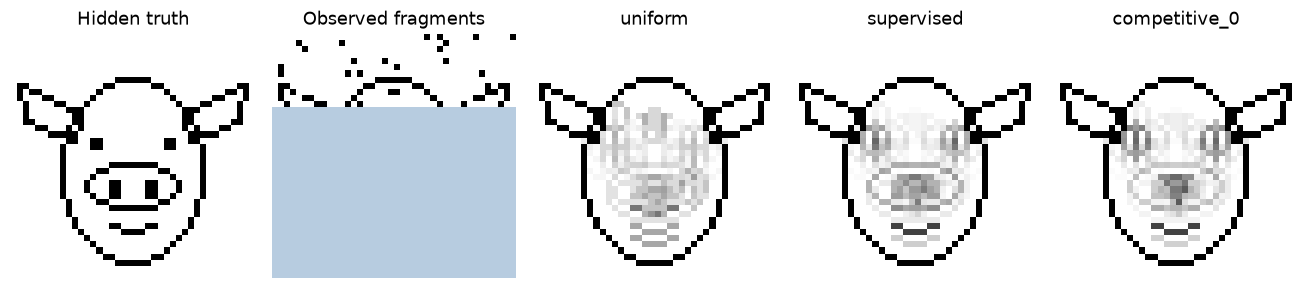

In [7]:
demo_id = int(library.test_ids[np.argmax(library.teacher_logp[0, library.test_ids])])
truth = library.images[demo_id]
mask = np.broadcast_to(np.arange(IMAGE_SIZE)[:,None] < round(.3*IMAGE_SIZE), truth.shape).copy()
observed = observe(truth, mask, FLIP_PROBABILITY, np.random.default_rng(37))
ll = encoder.evidence_scores(library.images, observed, mask, FLIP_PROBABILITY, 'vsa')
names = ['uniform', 'supervised', f'competitive_{first_seed}']
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
show_completion(axes[0], truth, "Hidden truth")
show_observation(axes[1], observed, mask)
for ax, name in zip(axes[2:], names):
    q = posterior(ll, priors[name])
    show_completion(ax, prediction(q, library.images), name)
    approximation = mean_field(ll, priors[name], library.states, CARDINALITIES, sweeps=25, seed=7)
    print(name, "mean-field TV from full-candidate result:",
          round(float(.5*np.abs(approximation['joint']-q).sum()), 4))
fig.tight_layout(); fig.savefig(OUT / "example_completion.png", dpi=160); plt.show()

## Inhibition ablation

Fit the first seed again with homeostatic strength zero, using the same unlabeled observations and shuffle order. Compare hard occupancy and unit preferences. This control tests the contribution of inhibition for this run. Homeostasis can encourage balanced use without producing semantic categories, so occupancy must be read alongside the feature and completion results.

In [8]:
without_inhibition = CompetitiveHebbianPrior(
    CARDINALITIES, n_units=N_UNITS, learning_rate=LEARNING_RATE,
    temperature=TEMPERATURE, homeostasis=0, usage_rate=USAGE_RATE, seed=first_seed)
without_inhibition.fit(training_features, epochs=EPOCHS, shuffle_seed=first_seed)
no_inhibition_winners = without_inhibition.predict_proba(training_features).argmax(axis=1)
no_inhibition_occupancy = np.bincount(no_inhibition_winners, minlength=N_UNITS)/len(training_features)
print("No inhibition occupancy:", no_inhibition_occupancy.round(3))
print("Configured inhibition occupancy:", occupancy_by_seed[first_seed].round(3))

summary = dict(training_draws=len(training_features), epochs=EPOCHS, n_units=N_UNITS,
               learning_rate=LEARNING_RATE, temperature=TEMPERATURE,
               homeostasis=HOMEOSTASIS, model_seeds=list(MODEL_SEEDS),
               heldout_trials=len(trials), seed_diagnostics=evaluation_summaries,
               no_inhibition_occupancy=no_inhibition_occupancy.tolist(),
               training_uses_category_labels=False,
               feature_vocabulary_supplied=True)
(OUT / 'comparison_summary.json').write_text(json.dumps(summary, indent=2))
for model_seed, trained in models.items():
    np.savez(OUT / f'weights_seed_{model_seed}.npz',
             category_weights=trained.category_weights, usage=trained.usage,
             **{f'feature_{j}': w for j,w in enumerate(trained.feature_weights)})
print("Saved reports, weights, and figures to", OUT)

No inhibition occupancy: [0.068 0.348 0.584]
Configured inhibition occupancy: [0.335 0.307 0.359]
Saved reports, weights, and figures to C:\NEU_172L\vsa_gestalt_closure_hebbian\outputs\competitive


## Interpreting the result

The learner discovers anonymous prototypes over supplied feature values. The number of units, competition temperature, inhibition strength and learning rate are explicit assumptions. Different seeds and stream orders can yield different partitions. Soft unit activity and final hard occupancy measure different things.

The post-hoc name alignment belongs to evaluation. Both full-candidate and iterative completion use the anonymous learned mixture directly. Uniform preferences and supervised Hebbian training provide reference conditions on identical trials. A low training loss or evenly used units alone does not establish accurate closure.

To use this learner in the full learned-prior experiment, choose `CATEGORY_LEARNING = "competitive"`. In that mode the cue section names anonymous units. The supervised Hebbian notebook remains available for checking equivalence with batch counting.